/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/tmp/ipykernel_1044/433464062.py:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  q_values[action]+=(reward-q_values[action])/counts[action]


Number of arms: 10

Epsilon-Greedy Results
Q-values: [-0.08 -0.03 -0.   -0.27 -0.04 -1.79 -0.01  0.19 -0.46 -0.39]
Arm selection counts: [  8  14 219   6  33   1 173  26  11   9]
Average reward: -0.023047385165101592


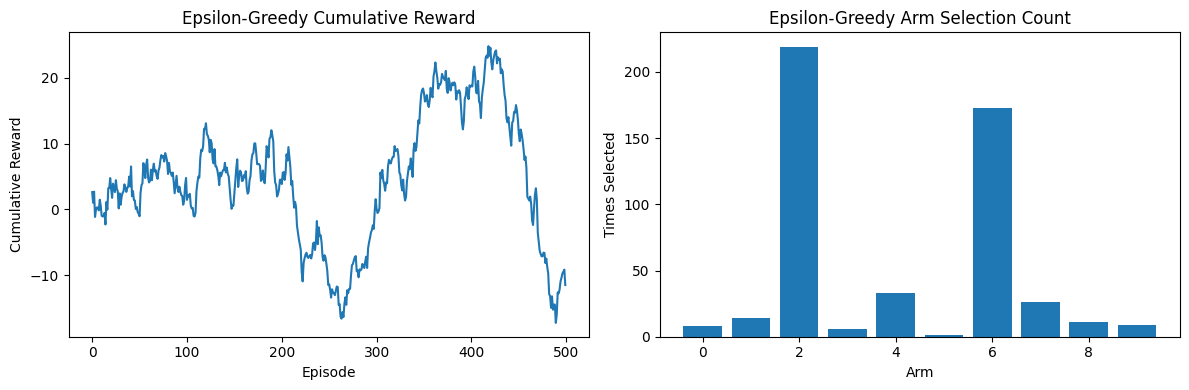

In [3]:
!pip install gym_bandits
import gym
import gym_bandits
import numpy as np
import matplotlib.pyplot as plt
np.bool8=np.bool_
base_env=gym.make("MultiarmedBandits-v0")
env=base_env.unwrapped
n_arms=env.action_space.n
episodes=500
print("Number of arms:",n_arms)
epsilon=0.1
q_values=np.zeros(n_arms)
counts=np.zeros(n_arms)
rewards=[]
for episode in range(episodes):
  env.reset()
  if np.random.rand()<epsilon:
    action = env.action_space.sample()
  else:
    action=np.argmax(q_values)
  observation,reward,done,info=env.step(action)
  counts[action]+=1
  q_values[action]+=(reward-q_values[action])/counts[action]
  rewards.append(reward)
print("\nEpsilon-Greedy Results")
print("Q-values:", np.round(q_values, 2))
print("Arm selection counts:", counts.astype(int))
print("Average reward:", np.mean(rewards))
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(np.cumsum(rewards))
plt.title("Epsilon-Greedy Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts)
plt.title("Epsilon-Greedy Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()


/tmp/ipykernel_1044/559913922.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  q_values_softmax[action]+=(reward-q_values_softmax[action])/counts_softmax[action]



Softmax Results
Q-values: [ 0.18 -0.12 -1.35  0.09  0.1   0.1   0.16 -0.24 -1.03  0.07]
Arm selection counts: [61 55  9 61 58 59 83 53  3 58]
Average reward: 0.020569940669512576


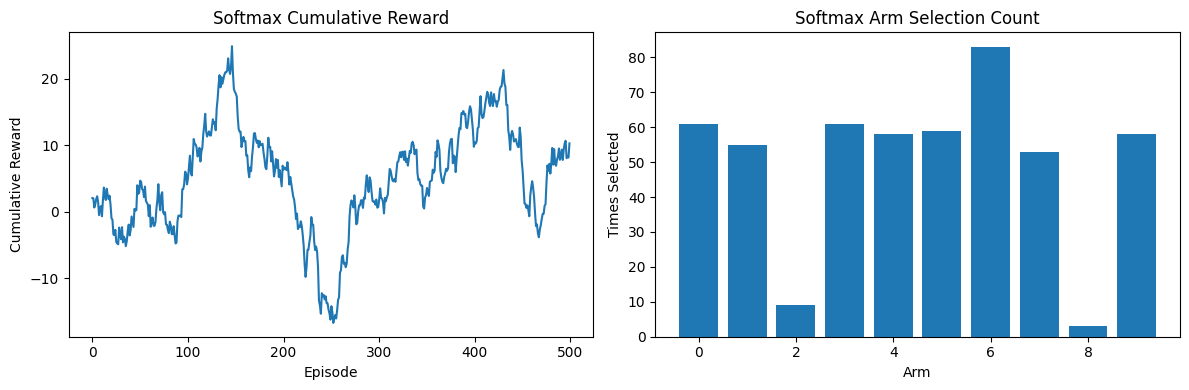

In [4]:
temperature=0.5
q_values_softmax=np.zeros(n_arms)
counts_softmax=np.zeros(n_arms)
rewards_softmax=[]
for episode in range(episodes):
  env.reset()
  probabilities=np.exp(q_values_softmax/temperature)
  probabilities=probabilities/np.sum(probabilities)
  action=np.random.choice(n_arms,p=probabilities)
  observation,reward,done,info=env.step(action)
  counts_softmax[action]+=1
  q_values_softmax[action]+=(reward-q_values_softmax[action])/counts_softmax[action]
  rewards_softmax.append(reward)
print("\nSoftmax Results")
print("Q-values:", np.round(q_values_softmax, 2))
print("Arm selection counts:", counts_softmax.astype(int))
print("Average reward:", np.mean(rewards_softmax))
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(np.cumsum(rewards_softmax))
plt.title("Softmax Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts_softmax)
plt.title("Softmax Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()



In [5]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
arms=["Video Lectures","Interactive Quizzes","Gamified Modules"]
probabilities=[0.6,0.4,0.7]
n_arms=len(arms)
rounds=1000
counts_ucb=np.zeros(n_arms)
values_ucb=np.zeros(n_arms)
rewards_ucb=[]
cumulative_rewards_ucb=[]
total_reward=0
for t in range(rounds):
  if t<n_arms:
    action=t
  else:
    confidence=np.sqrt((2*np.log(t+1)))
    ucb = values_ucb + confidence
    action = np.argmax(ucb)
reward = np.random.binomial(1, probabilities[action])
counts_ucb[action] += 1
values_ucb[action] += (
        reward - values_ucb[action]
    ) / counts_ucb[action]
total_reward += reward
rewards_ucb.append(reward)
cumulative_rewards_ucb.append(total_reward)
for i in range(n_arms):
    print(arms[i], "selected", int(counts_ucb[i]), "times")
print("Total Reward =", total_reward)



Video Lectures selected 1 times
Interactive Quizzes selected 0 times
Gamified Modules selected 0 times
Total Reward = 1


In [6]:
alpha = np.ones(n_arms)

# Initialize beta values of the Beta distribution
beta = np.ones(n_arms)

# Initialize arm selection counts
counts_ts = np.zeros(n_arms)

# Store rewards obtained
rewards_ts = []

# Store cumulative rewards
cumulative_rewards_ts = []

# Reset total reward
total_reward = 0

# Run Thompson Sampling
for t in range(rounds):
    samples = np.random.beta(alpha, beta)
    action = np.argmax(samples)
    reward = np.random.binomial(1, probabilities[action])
    counts_ts[action] += 1
    if reward == 1:
        alpha[action] += 1
    else:
        beta[action] += 1
    total_reward += reward
    rewards_ts.append(reward)
    cumulative_rewards_ts.append(total_reward)
for i in range(n_arms):
    print(arms[i], "selected", int(counts_ts[i]), "times")
print("Total Reward =", total_reward)

Video Lectures selected 101 times
Interactive Quizzes selected 6 times
Gamified Modules selected 893 times
Total Reward = 701


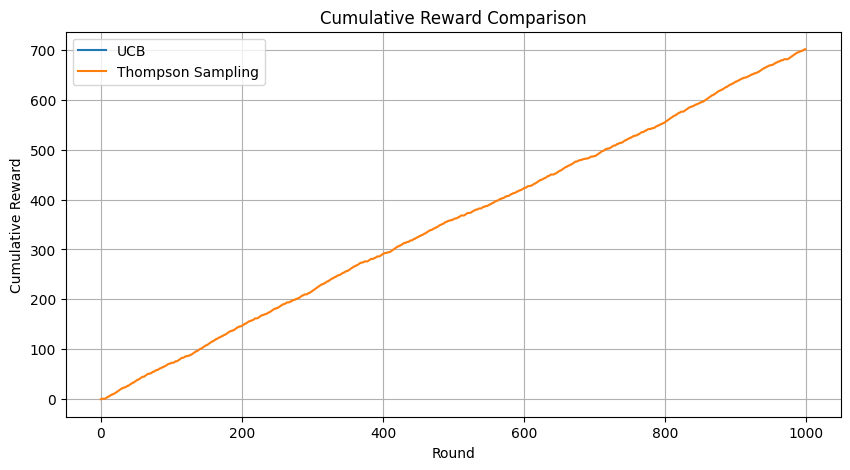

In [7]:
plt.figure(figsize=(10,5))
plt.plot(cumulative_rewards_ucb,label="UCB")
plt.plot(cumulative_rewards_ts, label="Thompson Sampling")
plt.xlabel("Round")
plt.ylabel("Cumulative Reward")
plt.title("Cumulative Reward Comparison")
plt.legend()
plt.grid()
plt.show()

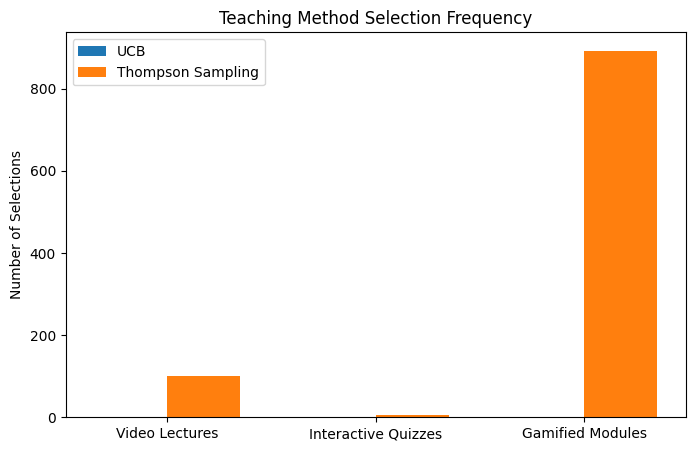

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [8]:
x = np.arange(n_arms)
width = 0.35
plt.figure(figsize=(8,5))
plt.bar(x-width/2,
        counts_ucb,
        width,
        label="UCB")
plt.bar(x+width/2,
        counts_ts,
        width,
        label="Thompson Sampling")
plt.xticks(x, arms)
plt.ylabel("Number of Selections")
plt.title("Teaching Method Selection Frequency")
plt.legend()
plt.show()